# Q3

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
import torch.backends.cudnn as cudnn
import numpy as np
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import time
import os
from PIL import Image
from tempfile import TemporaryDirectory

cudnn.benchmark = True
plt.ion()   # interactive mode

In [ ]:
# Data augmentation and normalization for training
# Just normalization for validation
data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

data_dir = './hymenoptera_data'
image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x),
                                          data_transforms[x])
                  for x in ['train', 'val']}
dataloaders = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=4,
                                             shuffle=True, num_workers=4)
              for x in ['train', 'val']}
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}
class_names = image_datasets['train'].classes


device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using xpu device


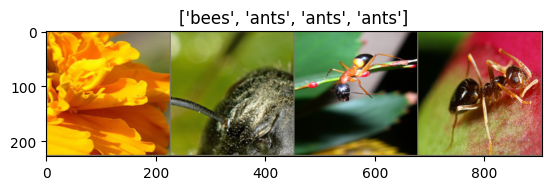

In [3]:
def imshow(inp, title=None):
    """Display image for Tensor."""
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.pause(0.001)  # pause a bit so that plots are updated


# Get a batch of training data
inputs, classes = next(iter(dataloaders['train']))

# Make a grid from batch
out = torchvision.utils.make_grid(inputs)

imshow(out, title=[class_names[x] for x in classes])

In [4]:
def train_model(model, criterion, optimizer, scheduler, num_epochs=25):
    since = time.time()

    # Create a temporary directory to save training checkpoints
    with TemporaryDirectory() as tempdir:
        best_model_params_path = os.path.join(tempdir, 'best_model_params.pt')

        torch.save(model.state_dict(), best_model_params_path)
        best_acc = 0.0

        for epoch in range(num_epochs):
            print(f'Epoch {epoch}/{num_epochs - 1}')
            print('-' * 10)

            # Each epoch has a training and validation phase
            for phase in ['train', 'val']:
                if phase == 'train':
                    model.train()  # Set model to training mode
                else:
                    model.eval()   # Set model to evaluate mode

                running_loss = 0.0
                running_corrects = 0

                # Iterate over data.
                for inputs, labels in dataloaders[phase]:
                    inputs = inputs.to(device)
                    labels = labels.to(device)

                    # zero the parameter gradients
                    optimizer.zero_grad()

                    # forward
                    # track history if only in train
                    with torch.set_grad_enabled(phase == 'train'):
                        outputs = model(inputs)
                        _, preds = torch.max(outputs, 1)
                        loss = criterion(outputs, labels)

                        # backward + optimize only if in training phase
                        if phase == 'train':
                            loss.backward()
                            optimizer.step()

                    # statistics
                    running_loss += loss.item() * inputs.size(0)
                    running_corrects += torch.sum(preds == labels.data)
                if phase == 'train':
                    scheduler.step()

                epoch_loss = running_loss / dataset_sizes[phase]
                epoch_acc = running_corrects.double() / dataset_sizes[phase]

                print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

                # deep copy the model
                if phase == 'val' and epoch_acc > best_acc:
                    best_acc = epoch_acc
                    torch.save(model.state_dict(), best_model_params_path)

            print()

        time_elapsed = time.time() - since
        print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
        print(f'Best val Acc: {best_acc:4f}')

        # load best model weights
        model.load_state_dict(torch.load(best_model_params_path, weights_only=True))
    return model

In [5]:
def visualize_model(model, num_images=6):
    was_training = model.training
    model.eval()
    images_so_far = 0
    fig = plt.figure()

    with torch.no_grad():
        for i, (inputs, labels) in enumerate(dataloaders['val']):
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            for j in range(inputs.size()[0]):
                images_so_far += 1
                ax = plt.subplot(num_images//2, 2, images_so_far)
                ax.axis('off')
                ax.set_title(f'predicted: {class_names[preds[j]]}')
                imshow(inputs.cpu().data[j])

                if images_so_far == num_images:
                    model.train(mode=was_training)
                    return
        model.train(mode=was_training)

### Part a - AS Fine tuning model

In [11]:
model_ft = models.resnet18(weights='IMAGENET1K_V1')
num_ftrs = model_ft.fc.in_features
# Here the size of each output sample is set to 2.
# Alternatively, it can be generalized to ``nn.Linear(num_ftrs, len(class_names))``.
model_ft.fc = nn.Linear(num_ftrs, 2)

model_ft = model_ft.to(device)

criterion = nn.CrossEntropyLoss()

# Observe that all parameters are being optimized
optimizer_ft = optim.SGD(model_ft.parameters(), lr=0.001, momentum=0.9)

# Decay LR by a factor of 0.1 every 7 epochs
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)

In [12]:
model_ft = train_model(model_ft, criterion, optimizer_ft, exp_lr_scheduler,
                       num_epochs=25)

Epoch 0/24
----------
train Loss: 0.6646 Acc: 0.6926
val Loss: 0.3244 Acc: 0.8562

Epoch 1/24
----------
train Loss: 0.5111 Acc: 0.7869
val Loss: 0.2745 Acc: 0.9216

Epoch 2/24
----------
train Loss: 0.4807 Acc: 0.7992
val Loss: 0.4167 Acc: 0.8627

Epoch 3/24
----------
train Loss: 0.3660 Acc: 0.8443
val Loss: 0.2140 Acc: 0.9020

Epoch 4/24
----------
train Loss: 0.4761 Acc: 0.8074
val Loss: 0.1914 Acc: 0.9281

Epoch 5/24
----------
train Loss: 0.4184 Acc: 0.8402
val Loss: 0.1833 Acc: 0.9281

Epoch 6/24
----------
train Loss: 0.4575 Acc: 0.8033
val Loss: 0.7331 Acc: 0.7974

Epoch 7/24
----------
train Loss: 0.3831 Acc: 0.8525
val Loss: 0.2287 Acc: 0.9020

Epoch 8/24
----------
train Loss: 0.2943 Acc: 0.8607
val Loss: 0.1938 Acc: 0.9216

Epoch 9/24
----------
train Loss: 0.2660 Acc: 0.9016
val Loss: 0.2129 Acc: 0.9085

Epoch 10/24
----------
train Loss: 0.2718 Acc: 0.8975
val Loss: 0.1676 Acc: 0.9216

Epoch 11/24
----------
train Loss: 0.2324 Acc: 0.9098
val Loss: 0.1583 Acc: 0.9412

Ep

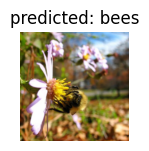

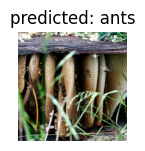

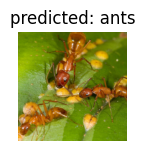

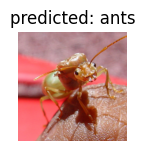

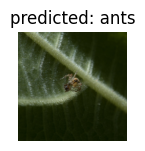

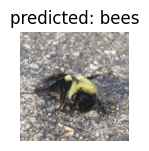

In [13]:
visualize_model(model_ft)

### Part b - AS Fixed feature extractor

In [8]:
model_conv = torchvision.models.resnet18(weights='IMAGENET1K_V1')
for param in model_conv.parameters():
    param.requires_grad = False

# Parameters of newly constructed modules have requires_grad=True by default
num_ftrs = model_conv.fc.in_features
model_conv.fc = nn.Linear(num_ftrs, 2)

model_conv = model_conv.to(device)

criterion = nn.CrossEntropyLoss()

# Observe that only parameters of final layer are being optimized as
# opposed to before.
optimizer_conv = optim.SGD(model_conv.fc.parameters(), lr=0.001, momentum=0.9)

# Decay LR by a factor of 0.1 every 7 epochs
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_conv, step_size=7, gamma=0.1)

In [9]:
model_conv = train_model(model_conv, criterion, optimizer_conv,
                         exp_lr_scheduler, num_epochs=25)

Epoch 0/24
----------
train Loss: 0.5886 Acc: 0.6844
val Loss: 0.2878 Acc: 0.8758

Epoch 1/24
----------
train Loss: 0.6317 Acc: 0.6967
val Loss: 0.1695 Acc: 0.9412

Epoch 2/24
----------
train Loss: 0.4886 Acc: 0.7746
val Loss: 0.2374 Acc: 0.9020

Epoch 3/24
----------
train Loss: 0.3155 Acc: 0.8689
val Loss: 0.2531 Acc: 0.9085

Epoch 4/24
----------
train Loss: 0.5081 Acc: 0.8156
val Loss: 0.2857 Acc: 0.8954

Epoch 5/24
----------
train Loss: 0.5929 Acc: 0.7664
val Loss: 0.1821 Acc: 0.9346

Epoch 6/24
----------
train Loss: 0.4583 Acc: 0.8074
val Loss: 0.2489 Acc: 0.9085

Epoch 7/24
----------
train Loss: 0.4004 Acc: 0.8525
val Loss: 0.2229 Acc: 0.9216

Epoch 8/24
----------
train Loss: 0.3957 Acc: 0.8279
val Loss: 0.2100 Acc: 0.9216

Epoch 9/24
----------
train Loss: 0.3572 Acc: 0.8484
val Loss: 0.2455 Acc: 0.8954

Epoch 10/24
----------
train Loss: 0.3765 Acc: 0.8156
val Loss: 0.1939 Acc: 0.9412

Epoch 11/24
----------
train Loss: 0.3848 Acc: 0.8115
val Loss: 0.1853 Acc: 0.9281

Ep

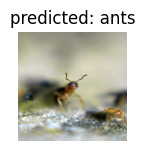

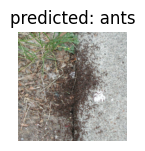

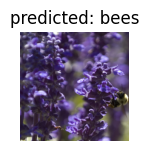

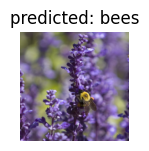

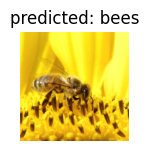

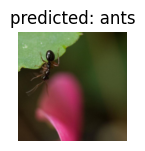

In [10]:
visualize_model(model_conv)

plt.ioff()
plt.show()

Fine tuning and fixed feature extraction represent two distinct approaches to transfer learning using pre trained models like ResNet18. In fine tuning the entire network has its weights updated with no layers frozen. It meaning the optimizer targets all model parameters  and this results in slower training speeds and higher memory consumption because gradients must be computed and backpropagated through every layer. Fixed feature extraction freezes all backbone layers and trains only the newly initialized final classification layer by passing solely the final layer parameters to the optimizer. This approach is much faster and consumes less memory due to minimal gradient storage requirements.